# 02 Procesamiento de texto, recuperación secuencial e indexación

**Nombre:** Joshua Daniel Menendez Farias

**Fecha:** 28-10-2026

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [1]:
import nltk
import re
import time
import tarfile
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

nltk.download('gutenberg', quiet=True)
from nltk.corpus import gutenberg

corpus_nltk = {}
docs_nltk = gutenberg.fileids()

for doc_id in docs_nltk:
    texto = gutenberg.raw(doc_id)
    # Tokenización y normalización: minúsculas y remoción de puntuación
    tokens = re.findall(r'\b[a-z]+\b', texto.lower())
    corpus_nltk[doc_id] = tokens

print(f"Número total de documentos: {len(corpus_nltk)}")
for doc_id, tokens in corpus_nltk.items():
    print(f"Documento: {doc_id} | Tamaño: {len(tokens)} tokens")

print("\nConfiguración documentada: Textos convertidos a minúsculas y filtrados usando la expresión regular r'\\b[a-z]+\\b' para eliminar puntuación, números y caracteres especiales.")

Número total de documentos: 18
Documento: austen-emma.txt | Tamaño: 161600 tokens
Documento: austen-persuasion.txt | Tamaño: 84121 tokens
Documento: austen-sense.txt | Tamaño: 120733 tokens
Documento: bible-kjv.txt | Tamaño: 791842 tokens
Documento: blake-poems.txt | Tamaño: 6934 tokens
Documento: bryant-stories.txt | Tamaño: 46611 tokens
Documento: burgess-busterbrown.txt | Tamaño: 16327 tokens
Documento: carroll-alice.txt | Tamaño: 27333 tokens
Documento: chesterton-ball.txt | Tamaño: 82677 tokens
Documento: chesterton-brown.txt | Tamaño: 73286 tokens
Documento: chesterton-thursday.txt | Tamaño: 58724 tokens
Documento: edgeworth-parents.txt | Tamaño: 170737 tokens
Documento: melville-moby_dick.txt | Tamaño: 218361 tokens
Documento: milton-paradise.txt | Tamaño: 80493 tokens
Documento: shakespeare-caesar.txt | Tamaño: 20800 tokens
Documento: shakespeare-hamlet.txt | Tamaño: 30266 tokens
Documento: shakespeare-macbeth.txt | Tamaño: 18272 tokens
Documento: whitman-leaves.txt | Tamaño: 1

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [2]:
def busqueda_secuencial(corpus, query):
    resultados = []
    # Lazo 1: recorre los documentos
    for doc_id, tokens in corpus.items():
        # Lazo 2: recorre los tokens
        for token in tokens:
            if token == query:
                if doc_id not in resultados:
                    resultados.append(doc_id)
                break
    return resultados

t_frec = "the"
t_poco_frec = "alice"
t_inexistente = "computadora"

print(f"Docs con término frecuente '{t_frec}':", busqueda_secuencial(corpus_nltk, t_frec))
print(f"Docs con término poco frecuente '{t_poco_frec}':", busqueda_secuencial(corpus_nltk, t_poco_frec))
print(f"Docs con término inexistente '{t_inexistente}':", busqueda_secuencial(corpus_nltk, t_inexistente))

Docs con término frecuente 'the': ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
Docs con término poco frecuente 'alice': ['carroll-alice.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt']
Docs con término inexistente 'computadora': []


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [3]:
def medir_secuencial(corpus, query, repeticiones=30):
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()
        busqueda_secuencial(corpus, query)
        fin = time.perf_counter_ns()
        tiempos.append((fin - inicio) / 1_000_000) # Convertir a milisegundos
    return np.mean(tiempos)

t_frec = "the"
t_poco_frec = "alice"
t_inexistente = "computadora"

print(f"Tiempo medio (30 ejecuciones) '{t_frec}': {medir_secuencial(corpus_nltk, t_frec):.4f} ms")
print(f"Tiempo medio (30 ejecuciones) '{t_poco_frec}': {medir_secuencial(corpus_nltk, t_poco_frec):.4f} ms")
print(f"Tiempo medio (30 ejecuciones) '{t_inexistente}': {medir_secuencial(corpus_nltk, t_inexistente):.4f} ms")

Tiempo medio (30 ejecuciones) 'the': 0.0158 ms
Tiempo medio (30 ejecuciones) 'alice': 71.7139 ms
Tiempo medio (30 ejecuciones) 'computadora': 72.3749 ms


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [4]:
def construir_indice(corpus):
    indice = {}
    for doc_id, tokens in corpus.items():
        for token in set(tokens):
            if token not in indice:
                indice[token] = []
            indice[token].append(doc_id)
    return indice

indice_nltk = construir_indice(corpus_nltk)

def df_termino(indice, termino):
    return len(indice.get(termino, []))

def consulta_and(indice, t1, t2):
    return list(set(indice.get(t1, [])) & set(indice.get(t2, [])))

def consulta_or(indice, t1, t2):
    return list(set(indice.get(t1, [])) | set(indice.get(t2, [])))

def consulta_not(indice, t1, todos_docs):
    return list(set(todos_docs) - set(indice.get(t1, [])))

print(f"DF de '{t_frec}': {df_termino(indice_nltk, t_frec)}")
print(f"DF de '{t_poco_frec}': {df_termino(indice_nltk, t_poco_frec)}")

todos_docs = list(corpus_nltk.keys())
print("\nConsulta AND ('alice' AND 'rabbit'):", consulta_and(indice_nltk, "alice", "rabbit"))
print("Consulta OR ('whale' OR 'ahab'):", consulta_or(indice_nltk, "whale", "ahab"))
print("Consulta NOT (NOT 'the'):", consulta_not(indice_nltk, "the", todos_docs))

DF de 'the': 18
DF de 'alice': 3

Consulta AND ('alice' AND 'rabbit'): ['chesterton-thursday.txt', 'carroll-alice.txt']
Consulta OR ('whale' OR 'ahab'): ['bryant-stories.txt', 'chesterton-ball.txt', 'whitman-leaves.txt', 'bible-kjv.txt', 'shakespeare-hamlet.txt', 'melville-moby_dick.txt']
Consulta NOT (NOT 'the'): []


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [5]:
def medir_indice(indice, query, repeticiones=30):
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()
        _ = indice.get(query, [])
        fin = time.perf_counter_ns()
        tiempos.append((fin - inicio) / 1_000_000)
    return np.mean(tiempos)

consultas = ["the", "alice", "computadora"]

for q in consultas:
    res_sec = sorted(busqueda_secuencial(corpus_nltk, q))
    res_ind = sorted(indice_nltk.get(q, []))
    
    t_sec = medir_secuencial(corpus_nltk, q)
    t_ind = medir_indice(indice_nltk, q)
    
    print(f"\nConsulta: '{q}' | ¿Resultados iguales?: {res_sec == res_ind}")
    print(f"Tiempo secuencial: {t_sec:.4f} ms | Tiempo índice: {t_ind:.4f} ms")



Consulta: 'the' | ¿Resultados iguales?: True
Tiempo secuencial: 0.0155 ms | Tiempo índice: 0.0005 ms

Consulta: 'alice' | ¿Resultados iguales?: True
Tiempo secuencial: 73.5236 ms | Tiempo índice: 0.0004 ms

Consulta: 'computadora' | ¿Resultados iguales?: True
Tiempo secuencial: 72.2082 ms | Tiempo índice: 0.0004 ms


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [6]:
import tarfile
import os
import re

def cargar_corpus_grande(ruta_tar, max_docs=1000):
    corpus_grande = {}
    documentos_validos = 0
    
    if not os.path.exists(ruta_tar):
        print(f"Error: El archivo {ruta_tar} no se encuentra.")
        return corpus_grande

    with tarfile.open(ruta_tar, 'r') as tar:
        for member in tar:
            if documentos_validos >= max_docs:
                break
            
            if member.isfile() and member.name.endswith('.txt'):
                f = tar.extractfile(member)
                if f:
                    try:
                        # Lectura directa de los textos
                        texto = f.read().decode('utf-8', errors='ignore')
                        tokens = re.findall(r'\b[a-z]+\b', texto.lower())
                        if tokens:
                            corpus_grande[member.name] = tokens
                            documentos_validos += 1
                    except Exception:
                        continue
                        
    return corpus_grande

# Ejecución
ruta_tar = 'txt-files.tar' # Verifica que el nombre y la ruta coincidan con tu archivo extraído
corpus_grande = cargar_corpus_grande(ruta_tar, max_docs=1000)
print(f"Cantidad de documentos válidos extraídos: {len(corpus_grande)}")

Cantidad de documentos válidos extraídos: 1000


In [13]:
ruta_tar = 'txt-files.tar' 
corpus_grande = cargar_corpus_grande(ruta_tar, max_docs=300)

print(f"Cantidad de documentos válidos extraídos: {len(corpus_grande)}")

if corpus_grande:
    indice_grande = construir_indice(corpus_grande)
    q_grande = "the"
    
    res_sec_g = sorted(busqueda_secuencial(corpus_grande, q_grande))
    res_ind_g = sorted(indice_grande.get(q_grande, []))
    
    print(f"\nCorpus grande - Consulta: '{q_grande}' | ¿Resultados iguales?: {res_sec_g == res_ind_g}")
    print(f"Tiempo secuencial: {medir_secuencial(corpus_grande, q_grande):.4f} ms")
    print(f"Tiempo índice: {medir_indice(indice_grande, q_grande):.4f} ms")

Cantidad de documentos válidos extraídos: 300

Corpus grande - Consulta: 'the' | ¿Resultados iguales?: True
Tiempo secuencial: 0.9604 ms
Tiempo índice: 0.0004 ms


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

In [14]:
def experimento_escalabilidad(corpus_completo, query="the"):
    tamaños = [50, 100, 200, 300]
    tiempos_secuencial = []
    tiempos_indice = []
    doc_ids = list(corpus_completo.keys())

    tamaños_validos = [n for n in tamaños if n <= len(doc_ids)]

    for n in tamaños_validos:
        subcorpus = {doc_id: corpus_completo[doc_id] for doc_id in doc_ids[:n]}
        
        t_sec = medir_secuencial(subcorpus, query)
        tiempos_secuencial.append(t_sec)
        
        indice_sub = construir_indice(subcorpus)
        t_ind = medir_indice(indice_sub, query)
        tiempos_indice.append(t_ind)

    plt.figure(figsize=(10, 6))
    plt.plot(tamaños_validos, tiempos_secuencial, marker='o', label='Secuencial')
    plt.plot(tamaños_validos, tiempos_indice, marker='s', label='Índice Invertido')
    plt.xlabel('Número de documentos')
    plt.ylabel('Tiempo medio (ms)')
    plt.title('Escalabilidad: Secuencial vs Índice Invertido')
    plt.legend()
    plt.grid(True)
    plt.show()

    return tamaños_validos, tiempos_secuencial, tiempos_indice

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

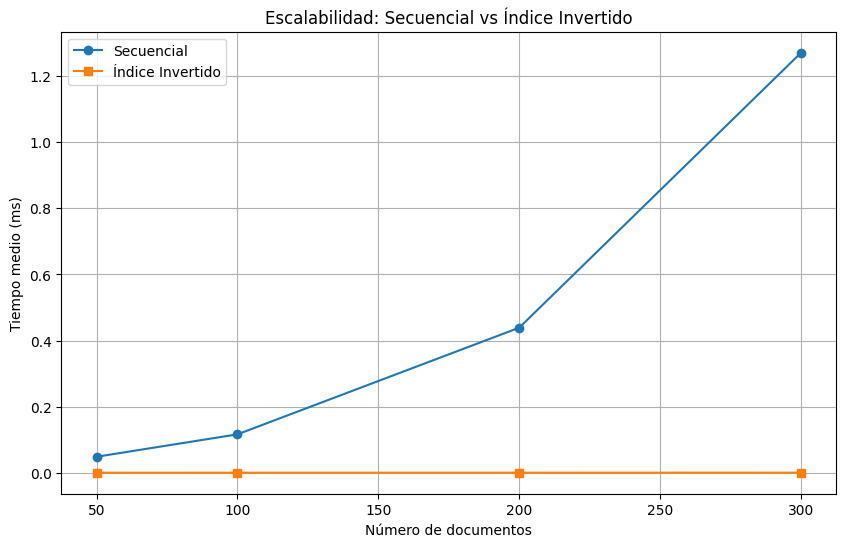


--- Modelo para Búsqueda Secuencial ---
Modelo Secuencial: t(n) = 0.004837n + -0.317456
R^2 = 0.9140


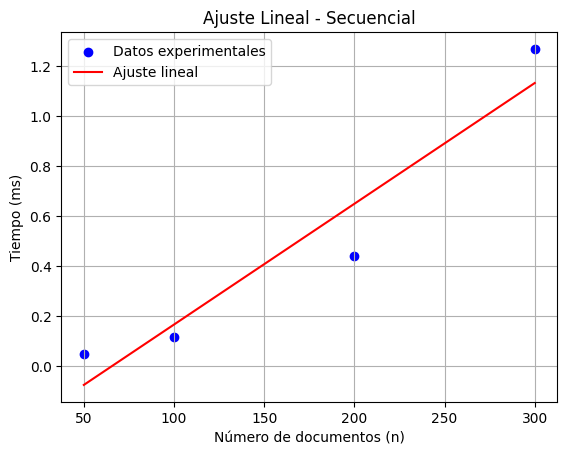


--- Modelo para Índice Invertido ---
Modelo Índice Invertido: t(n) = 0.000001n + 0.000383
R^2 = 0.8905


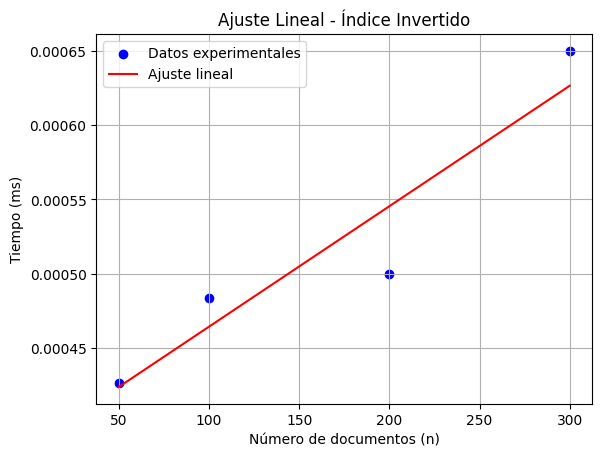

In [15]:
def regresion_lineal(tamaños, tiempos, metodo):
    X = np.array(tamaños).reshape(-1, 1)
    y = np.array(tiempos)
    
    modelo = LinearRegression()
    modelo.fit(X, y)
    
    a = modelo.coef_[0]
    b = modelo.intercept_
    r2 = modelo.score(X, y)
    
    print(f"Modelo {metodo}: t(n) = {a:.6f}n + {b:.6f}")
    print(f"R^2 = {r2:.4f}")
    
    plt.scatter(X, y, color='blue', label='Datos experimentales')
    plt.plot(X, modelo.predict(X), color='red', label='Ajuste lineal')
    plt.xlabel('Número de documentos (n)')
    plt.ylabel('Tiempo (ms)')
    plt.title(f'Ajuste Lineal - {metodo}')
    plt.legend()
    plt.grid(True)
    plt.show()

if corpus_grande:
    tamaños, t_sec_lista, t_ind_lista = experimento_escalabilidad(corpus_grande, query="the")
    
    print("\n--- Modelo para Búsqueda Secuencial ---")
    regresion_lineal(tamaños, t_sec_lista, "Secuencial")
    
    print("\n--- Modelo para Índice Invertido ---")
    regresion_lineal(tamaños, t_ind_lista, "Índice Invertido")

**Análisis del modelo para Búsqueda Secuencial**
El ajuste lineal ($t(n) = 0.004837n - 0.317456$) representa adecuadamente las mediciones empíricas, obteniendo un coeficiente de determinación de $R^2 = 0.9140$. La gráfica evidencia que el tiempo de ejecución crece de manera directamente proporcional a medida que aumenta la cantidad de documentos. Esto concuerda con su complejidad computacional teórica $\mathcal{O}(n)$, dado que la estructura de lazos anidados obliga al algoritmo a iterar exhaustivamente sobre cada nuevo token agregado al corpus.

**Análisis del modelo para Índice Invertido**
Para el índice invertido, el modelo ($t(n) = 0.000001n + 0.000383$) arroja una pendiente prácticamente nula. Los datos experimentales ilustran que los tiempos de recuperación se mantienen constantes en fracciones mínimas de milisegundo ante el crecimiento del corpus. Esto demuestra que la función de tiempo no depende de la variable $n$, lo que valida su complejidad algorítmica teórica $\mathcal{O}(1)$. Al utilizar la estructura de diccionario de Python (Hash Map), el índice localiza la lista de documentos asociados a un término de manera inmediata sin necesidad de recorridos secuenciales.